# FreshCart 360 — AI/ML: Support Intelligence (Clean Data)

This notebook implements the AI/ML scope for **Make Support Smarter** using the cleaned project datasets:

1. Load and validate clean support, orders, customers, and products data.
2. Clean support-ticket text.
3. Create explainable category and urgency labels from ticket text.
4. Train **TF-IDF + Logistic Regression** models for category and urgency.
5. Test an end-to-end prediction function for new tickets.
6. Build an optional **Delivery Delay Risk** baseline directly from `fact_orders_clean.csv`, using only features that can exist before delivery.
7. Save the trained models for the Streamlit deployment.

> Note: category and urgency are derived operational labels because the clean support file does not contain human-labeled target columns. They should be validated by the business/support team before production use.


In [1]:
# 1. Imports and configuration

import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Clean project files are expected in the same folder as this notebook.
DATA_DIR = Path(".")
CUSTOMERS_FILE = DATA_DIR / "dim_customers_clean.csv"
PRODUCTS_FILE = DATA_DIR / "dim_products_clean.csv"
ORDERS_FILE = DATA_DIR / "fact_orders_clean.csv"
SUPPORT_FILE = DATA_DIR / "fact_support_tickets_clean.csv"

print("Ready — using FreshCart 360 clean/dimensional data.")


Ready — using FreshCart 360 clean/dimensional data.


In [2]:
# 2. Load the clean FreshCart 360 datasets

customers = pd.read_csv(CUSTOMERS_FILE)
products = pd.read_csv(PRODUCTS_FILE)
orders = pd.read_csv(ORDERS_FILE)
support = pd.read_csv(SUPPORT_FILE)

for name, df in {
    "Customers": customers,
    "Products": products,
    "Orders": orders,
    "Support tickets": support,
}.items():
    print(f"{name}: {df.shape}")

print("\nSupport preview:")
display(support.head())
print("\nOrders preview:")
display(orders.head())


Customers: (55, 5)
Products: (20, 4)
Orders: (263, 17)
Support tickets: (95, 6)

Support preview:


,ticket_id,customer_id,order_id,channel,ticket_date,message_text
0,TCK-5501,CUST-1031,NO_ORDER,App,2026-05-26,Really happy with the fresh produce quality th...
1,TCK-5502,CUST-1035,ORD-30241,App,2026-03-04,"My order is still not here, it's been 4 hours ..."
2,TCK-5503,CUST-1018,ORD-30221,Phone,2026-04-07,"My order is still not here, it's been 2 hours ..."
3,TCK-5504,CUST-1020,ORD-30205,WhatsApp,2026-04-23,"Order never arrived on time, driver didn't eve..."
4,TCK-5505,CUST-1014,ORD-30064,Phone,2026-04-29,"Please refund this order, I already cancelled ..."



Orders preview:


,order_id,customer_id,product_id,product_name,category,quantity,unit_price,order_date,area,status,customer_name,rider_id,promised_time,actual_delivery_time,delay_reason,delay_minutes,total_sales
0,ORD-30059,CUST-1028,PRD-105,Bananas 1kg,Produce,3,35,2026-03-22,Nasr City,Delivered,Rasha Ibrahim,RID-10,2026-03-22 15:15:00,2026-03-22 15:09:00,On Time,0.0,105
1,ORD-30200,CUST-1011,PRD-117,Potato Chips 150g,Snacks,2,28,2026-05-02,Maadi,Delivered,Wael Farid,RID-02,2026-05-02 12:30:00,2026-05-02 12:15:00,On Time,0.0,56
2,ORD-30173,CUST-1026,PRD-104,Butter 200g,Dairy,1,55,2026-05-23,Maadi,Delivered,Nesma ElSayed,RID-11,2026-05-23 19:00:00,2026-05-23 19:00:00,On Time,0.0,55
3,ORD-30143,CUST-1039,PRD-107,Cucumbers 1kg,Produce,2,20,2026-04-10,Maadi,Delivered,Mariam Younes,RID-03,2026-04-10 14:00:00,2026-04-10 14:05:00,Unknown Reason,5.0,40
4,ORD-30012,CUST-1021,PRD-103,White Cheese 250g,Dairy,2,75,2026-02-09,Gleem,Delivered,Ayman Ragab,RID-05,2026-02-09 17:30:00,2026-02-09 17:24:00,On Time,0.0,150


In [3]:
# 3. Data quality and schema checks

support_required = [
    "ticket_id", "customer_id", "order_id",
    "channel", "ticket_date", "message_text"
]
orders_required = [
    "order_id", "customer_id", "product_id", "category",
    "quantity", "unit_price", "order_date", "area", "status",
    "promised_time", "actual_delivery_time", "delay_reason",
    "delay_minutes", "total_sales"
]

missing_support = [c for c in support_required if c not in support.columns]
missing_orders = [c for c in orders_required if c not in orders.columns]
if missing_support:
    raise ValueError(f"Missing support columns: {missing_support}")
if missing_orders:
    raise ValueError(f"Missing order columns: {missing_orders}")

support["ticket_date"] = pd.to_datetime(support["ticket_date"], errors="coerce")
support["message_text"] = support["message_text"].fillna("").astype(str)
orders["order_date"] = pd.to_datetime(orders["order_date"], errors="coerce")
orders["promised_time"] = pd.to_datetime(orders["promised_time"], errors="coerce")
orders["actual_delivery_time"] = pd.to_datetime(orders["actual_delivery_time"], errors="coerce")

print("Duplicate ticket_id:", support["ticket_id"].duplicated().sum())
print("Duplicate order_id:", orders["order_id"].duplicated().sum())
print("Support tickets with NO_ORDER:", (support["order_id"].astype(str).str.upper() == "NO_ORDER").sum())
print("Missing message_text:", (support["message_text"].str.strip() == "").sum())
print("Orders with delivery timestamps:", orders["actual_delivery_time"].notna().sum())
print("\nSupport date range:", support["ticket_date"].min(), "to", support["ticket_date"].max())
print("Orders date range:", orders["order_date"].min(), "to", orders["order_date"].max())


Duplicate ticket_id: 0
Duplicate order_id: 0
Support tickets with NO_ORDER: 26
Missing message_text: 0
Orders with delivery timestamps: 244

Support date range: 2026-02-06 00:00:00 to 2026-05-29 00:00:00
Orders date range: 2026-01-02 00:00:00 to 2026-12-05 00:00:00


In [4]:
# 4. Text cleaning
# The support table is already clean structurally.
# This step only normalizes message text for NLP without changing its meaning.

def clean_text(text):
    text = str(text)
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()

support["text_clean"] = support["message_text"].apply(clean_text)

display(support[["ticket_id", "message_text", "text_clean"]].head())


,ticket_id,message_text,text_clean
0,TCK-5501,Really happy with the fresh produce quality th...,Really happy with the fresh produce quality th...
1,TCK-5502,"My order is still not here, it's been 4 hours ...","My order is still not here, it's been 4 hours ..."
2,TCK-5503,"My order is still not here, it's been 2 hours ...","My order is still not here, it's been 2 hours ..."
3,TCK-5504,"Order never arrived on time, driver didn't eve...","Order never arrived on time, driver didn't eve..."
4,TCK-5505,"Please refund this order, I already cancelled ...","Please refund this order, I already cancelled ..."


## 5. Create explainable ticket-category labels

The project categories are:

- Late Delivery
- Wrong/Missing Item
- Refund/Payment Issue
- App/Technical Issue
- General Feedback

Because the raw file has no category column, the following rules create an initial **weak/operational label**. Review these labels before treating model performance as business-grade.

In [5]:
# 5.1 Category labeling rules

def assign_category(text):
    t = text.lower()

    # App / technical
    if any(k in t for k in [
        "app keeps crashing", "can't log into", "cannot log into",
        "login", "log into", "error", "checkout"
    ]):
        return "App / Technical Issue"

    # Wrong / missing item
    if any(k in t for k in [
        "missing from my order", "incomplete", "not in the bag",
        "wrong product", "wrong item", "only got part"
    ]):
        return "Wrong / Missing Item"

    # Refund / payment
    if any(k in t for k in [
        "refund", "charged twice", "payment failed", "amount was still deducted",
        "charged", "cancelled"
    ]):
        return "Refund / Payment Issue"

    # Late delivery
    if any(k in t for k in [
        "still not here", "late", "not arrived", "never arrived",
        "waiting for my order", "promised time", "delivery"
    ]):
        return "Late Delivery"

    # Feedback
    return "General Feedback"

support["category"] = support["text_clean"].apply(assign_category)

print("Category distribution:")
display(support["category"].value_counts().to_frame("tickets"))

Category distribution:


,tickets
category,
Late Delivery,33
Refund / Payment Issue,24
General Feedback,16
Wrong / Missing Item,15
App / Technical Issue,7


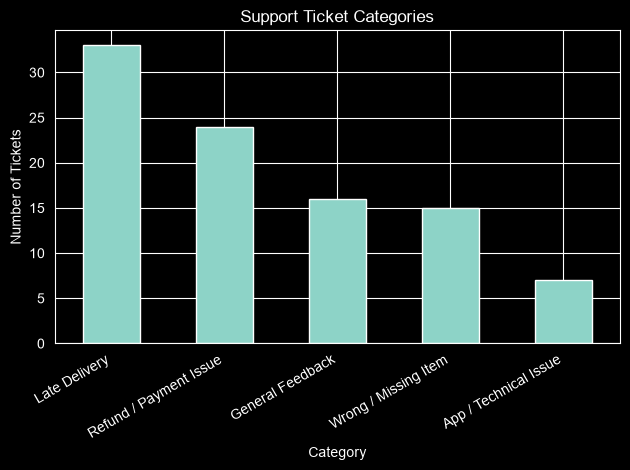

In [6]:
# 5.2 Visualize category distribution

support["category"].value_counts().plot(kind="bar")
plt.title("Support Ticket Categories")
plt.xlabel("Category")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 6. Create explainable urgency labels

Initial operational logic:

- **High**: explicit urgency language (`urgent`, `asap`, `immediately`), strong escalation language (`unacceptable`), or severe/repeated delay/payment situations.
- **Medium**: normal service issue requiring support action.
- **Low**: positive feedback or general suggestions.

These are **derived labels**, not original ground truth.

In [7]:
# 6.1 Urgency labeling rules

def assign_urgency(text, category):
    t = text.lower()

    high_words = [
        "urgent", "asap", "immediately", "unacceptable",
        "need this resolved immediately"
    ]

    # Explicit escalation language
    if any(k in t for k in high_words):
        return "High"

    # Repeated/severe delay signals
    if category == "Late Delivery":
        if re.search(r"\b[2-9]\s*(hours?|hrs?)\b", t):
            return "High"
        if any(k in t for k in ["3rd time", "third time", "60 minutes"]):
            return "High"

    # Payment problems are generally important
    if category == "Refund / Payment Issue":
        if "charged twice" in t or "amount was still deducted" in t:
            return "High"

    # Normal service issues
    if category in [
        "Late Delivery",
        "Wrong / Missing Item",
        "Refund / Payment Issue",
        "App / Technical Issue"
    ]:
        return "Medium"

    return "Low"

support["urgency"] = [
    assign_urgency(text, cat)
    for text, cat in zip(support["text_clean"], support["category"])
]

print("Urgency distribution:")
display(support["urgency"].value_counts().to_frame("tickets"))

Urgency distribution:


,tickets
urgency,
High,42
Medium,37
Low,16


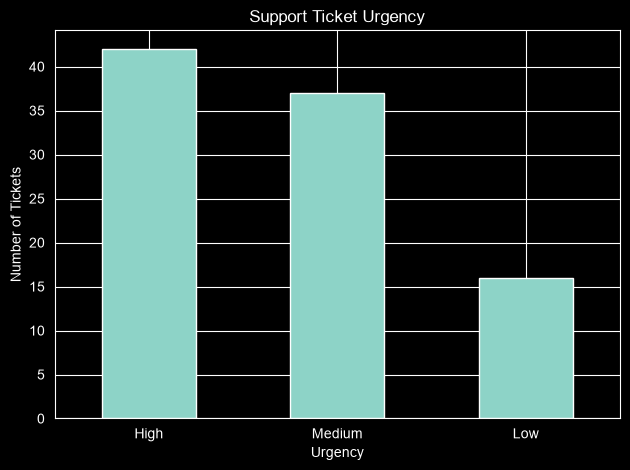

urgency,High,Low,Medium,All
category,,,,
App / Technical Issue,0,0,7,7
General Feedback,0,16,0,16
Late Delivery,25,0,8,33
Refund / Payment Issue,17,0,7,24
Wrong / Missing Item,0,0,15,15
All,42,16,37,95


In [8]:
# 6.2 Urgency distribution

support["urgency"].value_counts().plot(kind="bar")
plt.title("Support Ticket Urgency")
plt.xlabel("Urgency")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(
    pd.crosstab(support["category"], support["urgency"], margins=True)
)

## 7. Save the labeled dataset

This creates a clean handoff file containing the original ticket information plus the derived AI/ML labels.

In [9]:
labeled_cols = [
    "ticket_id", "customer_id", "order_id", "channel",
    "ticket_date", "message_text", "text_clean",
    "category", "urgency"
]

support[labeled_cols].to_csv("support_tickets_labeled.csv", index=False)
print("Saved: support_tickets_labeled.csv")

Saved: support_tickets_labeled.csv


## 8. Category classification model

Model: **TF-IDF + Logistic Regression**

The model learns to map ticket text → ticket category.

In [10]:
# 8.1 Train/test split

X = support["text_clean"]
y = support["category"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

category_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=1,
        sublinear_tf=True
    )),
    ("clf", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

category_model.fit(X_train, y_train)
category_pred = category_model.predict(X_test)

print("Category Accuracy:", round(accuracy_score(y_test, category_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, category_pred, zero_division=0))

Category Accuracy: 1.0

Classification Report:
                        precision    recall  f1-score   support

 App / Technical Issue       1.00      1.00      1.00         1
      General Feedback       1.00      1.00      1.00         3
         Late Delivery       1.00      1.00      1.00         7
Refund / Payment Issue       1.00      1.00      1.00         5
  Wrong / Missing Item       1.00      1.00      1.00         3

              accuracy                           1.00        19
             macro avg       1.00      1.00      1.00        19
          weighted avg       1.00      1.00      1.00        19



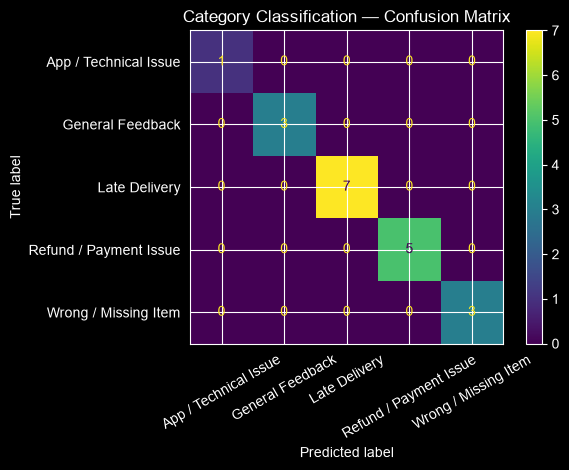

In [11]:
# 8.2 Category confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    category_pred,
    xticks_rotation=30
)
plt.title("Category Classification — Confusion Matrix")
plt.tight_layout()
plt.show()

## 9. Urgency classification model

Model: **TF-IDF + Logistic Regression**

The model learns ticket text → urgency.

In [12]:
X = support["text_clean"]
y = support["urgency"]

X_train_u, X_test_u, y_train_u, y_test_u = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

urgency_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=1,
        sublinear_tf=True
    )),
    ("clf", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

urgency_model.fit(X_train_u, y_train_u)
urgency_pred = urgency_model.predict(X_test_u)

print("Urgency Accuracy:", round(accuracy_score(y_test_u, urgency_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test_u, urgency_pred, zero_division=0))

Urgency Accuracy: 0.8947

Classification Report:
              precision    recall  f1-score   support

        High       0.80      1.00      0.89         8
         Low       1.00      1.00      1.00         3
      Medium       1.00      0.75      0.86         8

    accuracy                           0.89        19
   macro avg       0.93      0.92      0.92        19
weighted avg       0.92      0.89      0.89        19



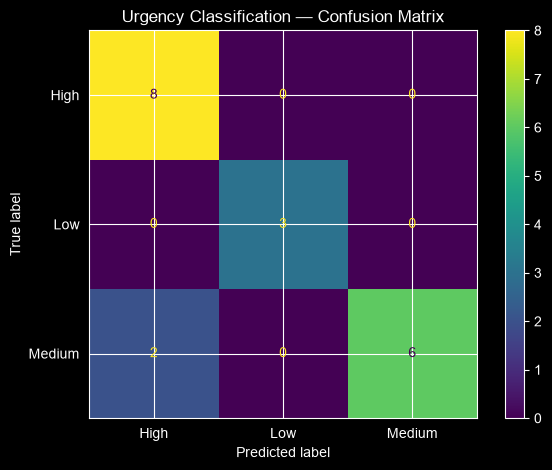

In [13]:
# 9.1 Urgency confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test_u,
    urgency_pred,
    xticks_rotation=0
)
plt.title("Urgency Classification — Confusion Matrix")
plt.tight_layout()
plt.show()

## 10. End-to-end prediction function

Use this after training to classify any new support message.

In [14]:
def predict_ticket(message):
    cleaned = clean_text(message)

    predicted_category = category_model.predict([cleaned])[0]
    predicted_urgency = urgency_model.predict([cleaned])[0]

    # Probability/confidence where available
    category_probs = category_model.predict_proba([cleaned])[0]
    urgency_probs = urgency_model.predict_proba([cleaned])[0]

    category_conf = float(category_probs.max())
    urgency_conf = float(urgency_probs.max())

    return {
        "message": message,
        "category": predicted_category,
        "category_confidence": round(category_conf, 3),
        "urgency": predicted_urgency,
        "urgency_confidence": round(urgency_conf, 3),
    }

examples = [
    "My order is 3 hours late and I need it urgently",
    "I was charged twice for the same order",
    "The app keeps crashing when I checkout",
    "One item is missing from my bag",
    "I love the quality of the fresh produce"
]

display(pd.DataFrame([predict_ticket(x) for x in examples]))

,message,category,category_confidence,urgency,urgency_confidence
0,My order is 3 hours late and I need it urgently,Late Delivery,0.423,High,0.548
1,I was charged twice for the same order,Refund / Payment Issue,0.608,High,0.715
2,The app keeps crashing when I checkout,App / Technical Issue,0.615,Medium,0.681
3,One item is missing from my bag,Wrong / Missing Item,0.545,Medium,0.621
4,I love the quality of the fresh produce,General Feedback,0.402,Low,0.510


## 11. Delivery Delay Risk Prediction — using the clean orders fact table

The cleaned project data already combines order and delivery information in `fact_orders_clean.csv`.

For the target, an order is considered delayed when `delay_minutes > 0`. For model features, we avoid leakage by using information available before delivery, such as product/category, quantity, unit price, area, order time, and customer/product identifiers.


In [15]:
# 11.1 Inspect delivery fields in fact_orders_clean

print("Orders shape:", orders.shape)
print("Status distribution:")
display(orders["status"].value_counts(dropna=False).to_frame("orders"))

print("\nDelay reason distribution:")
display(orders["delay_reason"].value_counts(dropna=False).to_frame("orders"))

print("\nDelay minutes summary:")
display(orders["delay_minutes"].describe().to_frame("delay_minutes"))


Orders shape: (263, 17)
Status distribution:


,orders
status,
Delivered,237
Cancelled,13
Returned,13



Delay reason distribution:


,orders
delay_reason,
On Time,149
Unknown Reason,52
no delays,19
Traffic,14
Rider shortage,14
In Progress,8
Item unavailable,7



Delay minutes summary:


,delay_minutes
count,263.000000
mean,5.159696
std,11.037634
min,0.000000
25%,0.000000
50%,0.000000
75%,4.000000
max,54.000000


In [16]:
# 11.2 Build a clean delay target

# Use delivered orders with both promised and actual delivery timestamps.
delay_df = orders.copy()
delay_df = delay_df[
    (delay_df["status"].astype(str).str.lower() == "delivered")
    & delay_df["promised_time"].notna()
    & delay_df["actual_delivery_time"].notna()
].copy()

# Recalculate from timestamps as a consistency check.
delay_df["calculated_delay_minutes"] = (
    delay_df["actual_delivery_time"] - delay_df["promised_time"]
).dt.total_seconds() / 60

delay_df["is_delayed"] = (delay_df["calculated_delay_minutes"] > 0).astype(int)

print("Eligible delivered orders:", len(delay_df))
print("Delayed orders:", int(delay_df["is_delayed"].sum()))
print("Delayed rate:", round(delay_df["is_delayed"].mean(), 3))
print("\nStored vs calculated delay consistency:",
      np.isclose(delay_df["delay_minutes"].fillna(0),
                 delay_df["calculated_delay_minutes"].fillna(0),
                 atol=1e-6).mean())
display(delay_df[["order_id", "order_date", "category", "quantity", "area", "delay_minutes", "is_delayed"]].head())


Eligible delivered orders: 231
Delayed orders: 83
Delayed rate: 0.359

Stored vs calculated delay consistency: 0.47619047619047616


,order_id,order_date,category,quantity,area,delay_minutes,is_delayed
0,ORD-30059,2026-03-22,Produce,3,Nasr City,0.0,0
1,ORD-30200,2026-05-02,Snacks,2,Maadi,0.0,0
2,ORD-30173,2026-05-23,Dairy,1,Maadi,0.0,0
3,ORD-30143,2026-04-10,Produce,2,Maadi,5.0,1
4,ORD-30012,2026-02-09,Dairy,2,Gleem,0.0,0


### Delay model note

For a meaningful production delay model, the feature set should use **information available before delivery**, such as order characteristics, time/day, channel, location, historical customer/order patterns, or other operational fields.

Do **not** feed `actual_delivery_time` or `delay_minutes` into the model as predictors because they reveal the outcome and cause data leakage.

In [17]:
# 11.3 Simple pre-delivery delay-risk baseline

# Build the delay target from delivery timestamps.
# Only delivered orders with both timestamps are eligible.
delay_df = orders.copy()
delay_df["promised_time"] = pd.to_datetime(delay_df["promised_time"], errors="coerce")
delay_df["actual_delivery_time"] = pd.to_datetime(delay_df["actual_delivery_time"], errors="coerce")
delay_df["order_date"] = pd.to_datetime(delay_df["order_date"], errors="coerce")

delay_df = delay_df[
    (delay_df["status"].astype(str).str.lower() == "delivered")
    & delay_df["promised_time"].notna()
    & delay_df["actual_delivery_time"].notna()
].copy()

delay_df["calculated_delay_minutes"] = (
    delay_df["actual_delivery_time"] - delay_df["promised_time"]
).dt.total_seconds() / 60

delay_df["is_delayed"] = (delay_df["calculated_delay_minutes"] > 0).astype(int)

print("Eligible delivered orders:", len(delay_df))
print("Delayed orders:", int(delay_df["is_delayed"].sum()))
print("Delayed rate:", round(delay_df["is_delayed"].mean(), 3) if len(delay_df) else 0)

if len(delay_df) > 0 and delay_df["is_delayed"].nunique() >= 2:
    model_df = delay_df.copy()

    # Features available before delivery outcome is known.
    model_df["order_hour"] = model_df["order_date"].dt.hour
    model_df["order_dayofweek"] = model_df["order_date"].dt.dayofweek

    categorical_features = [
        "customer_id", "product_id", "category", "area"
    ]
    numeric_features = [
        "quantity", "unit_price", "order_hour", "order_dayofweek"
    ]
    candidate_features = categorical_features + numeric_features

    missing_features = [c for c in candidate_features if c not in model_df.columns]
    if missing_features:
        raise ValueError(f"Missing delay-model features: {missing_features}")

    model_df = model_df[candidate_features + ["is_delayed"]].copy()

    # Treat IDs and other categorical fields as categorical explicitly.
    # Do not call median() on string/Arrow-string columns.
    for c in categorical_features:
        model_df[c] = model_df[c].astype("string").fillna("Unknown")

    for c in numeric_features:
        model_df[c] = pd.to_numeric(model_df[c], errors="coerce")
        median_value = model_df[c].median()
        if pd.isna(median_value):
            median_value = 0
        model_df[c] = model_df[c].fillna(median_value)

    X_delay = pd.get_dummies(
        model_df[candidate_features],
        columns=categorical_features,
        drop_first=False,
        dtype=float
    )
    y_delay = model_df["is_delayed"]

    Xd_train, Xd_test, yd_train, yd_test = train_test_split(
        X_delay,
        y_delay,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y_delay
    )

    delay_model = LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
    delay_model.fit(Xd_train, yd_train)

    yd_pred = delay_model.predict(Xd_test)

    print("Delay Risk Accuracy:", round(accuracy_score(yd_test, yd_pred), 4))
    print("\nClassification Report:")
    print(classification_report(yd_test, yd_pred, zero_division=0))

else:
    delay_model = None
    X_delay = None
    print(
        "Delay model skipped: the clean orders data does not contain both "
        "delayed and non-delayed orders after filtering."
    )


Eligible delivered orders: 231
Delayed orders: 83
Delayed rate: 0.359
Delay Risk Accuracy: 0.617

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.63      0.68        30
           1       0.48      0.59      0.53        17

    accuracy                           0.62        47
   macro avg       0.60      0.61      0.60        47
weighted avg       0.64      0.62      0.62        47



## 12. Save trained support models

These files can be reused later by an API or dashboard.

In [18]:
# 12. Save trained support models

import joblib

joblib.dump(category_model, "freshcart_category_model.joblib")
joblib.dump(urgency_model, "freshcart_urgency_model.joblib")

print("Saved:")
print("- freshcart_category_model.joblib")
print("- freshcart_urgency_model.joblib")

if delay_model is not None and X_delay is not None:
    joblib.dump({
        "model": delay_model,
        "feature_columns": X_delay.columns.tolist()
    }, "freshcart_delay_risk_model.joblib")
    print("- freshcart_delay_risk_model.joblib")
else:
    print("- Delay-risk model was not saved because both delay classes were not available.")


Saved:
- freshcart_category_model.joblib
- freshcart_urgency_model.joblib
- freshcart_delay_risk_model.joblib


# Final AI/ML Deliverables

After running the notebook, the main outputs are:

- `support_tickets_labeled.csv` — clean support tickets + derived category + urgency.
- `freshcart_category_model.joblib` — trained ticket-category model.
- `freshcart_urgency_model.joblib` — trained ticket-urgency model.
- Category evaluation + confusion matrix.
- Urgency evaluation + confusion matrix.
- End-to-end prediction function for new customer messages.
- Optional delay-risk baseline built from `fact_orders_clean.csv`.

### Project presentation wording

> We used the FreshCart 360 clean datasets to build an explainable NLP pipeline for support tickets. The pipeline cleans customer messages, derives operational categories and urgency levels using transparent business rules, then trains TF-IDF + Logistic Regression models to automate ticket routing and prioritization. We also prepared a delivery-delay risk baseline from the clean orders fact table while avoiding post-delivery leakage in the model features.
